<a href="https://colab.research.google.com/github/udamarla1/MobilePrice_Prediction_Regression_ML/blob/main/MobilePrice_Prediction_Regression_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workshop - I

## Objective:
In this module, we will explore various regression and classification models to evaluate their performance on a given dataset, ultimately determining which model delivers the best results:

- **1. Regression Models:**
     - Dataset Description

     - Conduct Exploratory Data Analysis (EDA) on the dataset.
      - a. Basic Information
      - b. Examine the Target Variable
      - c. Examine Feature Variables
      - d. Feature-Target Relationship
      - e. Check for Multicollinearity

     - Data pre-processing

     - Train and evaluate different regression models:
      - a. Simple Linear Regression
      - b. Polynomial Regression
     

- **2. Classification Models:**
     - Dataset Description

     - Conduct Exploratory Data Analysis (EDA) on the dataset.
      - a. Basic Information
      - b. Examine the Target Variable
      - c. Examine Feature Variables
      - d. Check for Multicollinearity

     - Data pre-processing

     - Train and evaluate different classification models:
      - a. Logistic Regression
      - b. K-Nearest Neighbours (KNN)
      - c. Naive Bayes

     - Hyperparameter tuning using techniques such as   GridSearchCV or RandomizedSearchCV

#1. Regression Models



## 1.1 Dataset Description

<center><img src="https://i.pcmag.com/imagery/articles/00p0Qzwvctko7LmNqSYnPAE-10..v1713208898.jpg" width=500/></center>

**Problem Statement:**

Develop a model that predicts the price range of mobile phones based on their features and specifications. The goal is to classify mobile devices into different price categories (e.g., low, medium, high) using attributes such as battery life, screen size, RAM, processor speed, and camera quality. This model will assist manufacturers, retailers, and consumers in understanding how various features contribute to the overall cost of mobile devices.

**Dataset:**
Dataset is taken from kaggle - <a href='https://www.kaggle.com/datasets/ganjerlawrence/mobile-phone-price-prediction-cleaned-dataset'>link</a>

This data set is a collection for information about various mobile phone type . it is a cleaned data set made available for beginners who want to learn on how to implement machine learning algorithms rather than spending time cleaning the data set. you can just concentrate on building your models

The columns available in the dataset are:-

- **Ratings:** This field contains the various rating given by customers
- **Ram:** This field contain the Ram capacity of the phone in GB
- **ROM:** This is field contains the number of space available in the phone in GB
- **Mobile_Size:** This is the int size of the screen
- **Primary_Cam:** This is the number of pixels of the Back camera
- **Selfi_Cam:** The number of Pixels of the front camera
- **Battery_Power:** The battery power
- **Price:** The price of the mobile phone in INR(indian Rupees)

All the fields are already in numerical values either `int` or `float`.



## 1.2 Importing the necessary libraries & modules

In [ ]:
# Import the warnings module, which allows control over warning messages
import warnings

# Suppress all warnings in the script
warnings.filterwarnings("ignore")

In [ ]:
# Importing libraries for numerical operations and data manipulation
import numpy as np     # For numerical computations
import pandas as pd    # For handling dataframes and data manipulation

# Importing libraries for data visualization
import matplotlib.pyplot as plt  # For plotting graphs
import seaborn as sns            # For enhanced visualizations

# Importing metrics for evaluating regression model performance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # Metrics to evaluate models

# Importing utilities for splitting data and applying feature transformations
from sklearn.model_selection import train_test_split  # For splitting data into training and testing sets


# Importing models for regression tasks
from sklearn.linear_model import LinearRegression     # For linear regression model


# Importing libraries for statistical analysis
from statsmodels.stats.outliers_influence import variance_inflation_factor  # To calculate VIF for multicollinearity
import statsmodels.api as sm   # For advanced statistical modeling

## 1.3 Loading the data

- `read_csv()` helps to load a csv file.
- `head()` helps to view the initial few rows of the dataset.

In [ ]:
# Load the dataset from a CSV file into a DataFrame
df = pd.read_csv('mobile_data.csv')

# Display the first five rows of the DataFrame to get an initial overview of the data
df.head()

,Ratings,RAM,ROM,Mobile_Size,Primary_Cam,Selfi_Cam,Battery_Power,Price
0,4.3,4.0,128.0,6.00,48,13.0,4000,24999
1,3.4,6.0,64.0,4.50,48,12.0,4000,15999
2,4.3,4.0,4.0,4.50,64,16.0,4000,15000
3,4.4,6.0,64.0,6.40,48,15.0,3800,18999
4,4.5,6.0,128.0,6.18,35,15.0,3800,18999


# 1.4 Exploratory Data Analysis (EDA)

#1.4.1 Basic Information

 Get an initial overview of the dataset to understand its structure, types of variables, and any immediate data quality issues.

- `info()` gives information about the dataset.
- `describe()` provides the basic statistical details about the dataset.

In [ ]:
# Display a summary of the Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 807 entries, 0 to 806
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Ratings        807 non-null    float64
 1   RAM            807 non-null    float64
 2   ROM            807 non-null    float64
 3   Mobile_Size    807 non-null    float64
 4   Primary_Cam    807 non-null    int64  
 5   Selfi_Cam      807 non-null    float64
 6   Battery_Power  807 non-null    int64  
 7   Price          807 non-null    int64  
dtypes: float64(5), int64(3)
memory usage: 50.6 KB


### Interpretation:
- Do all the columns have the correct data types?
  - Yes. All the columns are aligned with the proper data types.
- Are there any null values in the dataset?
  - No. There are no null values in the dataset.

In [ ]:
# Generate descriptive statistics for the numerical columns in the data
df.describe()

,Ratings,RAM,ROM,Mobile_Size,Primary_Cam,Selfi_Cam,Battery_Power,Price
count,807.000000,807.000000,807.000000,807.000000,807.000000,807.000000,807.000000,807.000000
mean,4.112639,5.941760,64.390335,5.620660,47.821561,8.868649,3278.859975,14269.167286
std,0.367830,2.056359,53.868626,3.957409,11.155916,4.547254,937.628801,23092.739983
min,2.800000,0.000000,2.000000,2.000000,5.000000,0.000000,1020.000000,479.000000
25%,3.900000,6.000000,32.000000,4.500000,48.000000,8.000000,3000.000000,984.000000
50%,4.100000,6.000000,32.000000,4.770000,48.000000,8.000000,3000.000000,1699.000000
75%,4.400000,6.000000,64.000000,6.300000,48.000000,12.000000,3800.000000,18994.500000
max,4.800000,12.000000,256.000000,44.000000,64.000000,23.000000,6000.000000,153000.000000


### Interpretation:
- Which features might contain outliers? Why?

  - **RAM:** The minimum value is 0.0 GB, which is unusual for a smartphone and likely indicates an outlier or missing data.

  - **Mobile_Size:** The maximum value is 44.0 inches, which is far larger than typical mobile devices, suggesting a potential outlier or data entry error.

  - **Selfi_Cam:** The minimum value is 0.0 MP, which could suggest an outlier or a phone without a front camera, but it's still unusual.

## 1.4.2 Distribution Analysis of the target variable

*Hint: Use the kdeplot*
- `sns.kdeplot()` visualizes the distribution of observations in a dataset.



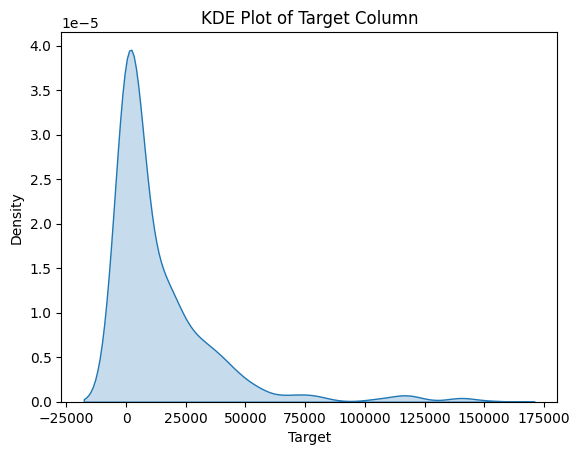

In [ ]:
# KDE plot of the target column
sns.kdeplot(df['Price'], shade=True)

# Adding labels and title
plt.xlabel('Target')
plt.ylabel('Density')
plt.title('KDE Plot of Target Column')

# Show plot
plt.show()

### Interpretation:
- What does the KDE plot of the target column indicate about the distribution?

  - The distribution is **right-skewed**, indicating that the majority of the target values are concentrated towards the lower end, with a long tail extending to the right.

- What does the shape of this distribution suggest about the nature of the target variable?

  - The right-skewed shape suggests that the target variable might represent something like prices, incomes, or sales figures, where lower values are more common, but there are a few instances of very high values.

- Are there any outliers or extreme values present in the target column?

  - Yes, the long tail on the right side suggests the presence of extreme values or outliers in the target column.

- Where is the peak of the distribution located?

  - The peak of the distribution is around the lower range, close to 0, which indicates that most of the target values are clustered at the lower end.

- How does the density change across the range of target values?

  - The density sharply decreases after the peak, indicating that higher target values are much less frequent in the dataset.


## 1.4.3 Outlier Analysis of the target variable

*Hint: Use the boxplot*
- `sns.boxplot()` helps to visualize the observations using a boxplot.

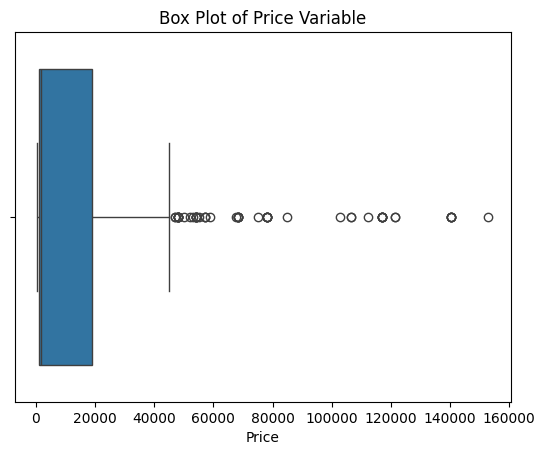

In [ ]:
# Outlier analysis using boxplot
sns.boxplot(x=df['Price'])
plt.title('Box Plot of Price Variable')
plt.show()

### Interpretation:
- Are there any outliers present in the "Price" variable?
  - Yes, there are several outliers, as indicated by the dots beyond the upper whisker. These outliers represent unusually high prices that deviate significantly from the rest of the data.

- Where is the median of the `Price` variable located?
  - The median is located near the lower end of the box, indicating that 50% of the data points fall below this value, which aligns with the right-skewed nature of the data.



## 1.4.4 Correlation Analysis of the dataset

*Hint: Use heatmap*
- `corr()` calculates the correlation between columns in a DataFrame.
- `sns.heatmap()` helps to visualize the correlation values as a color coded matrix.

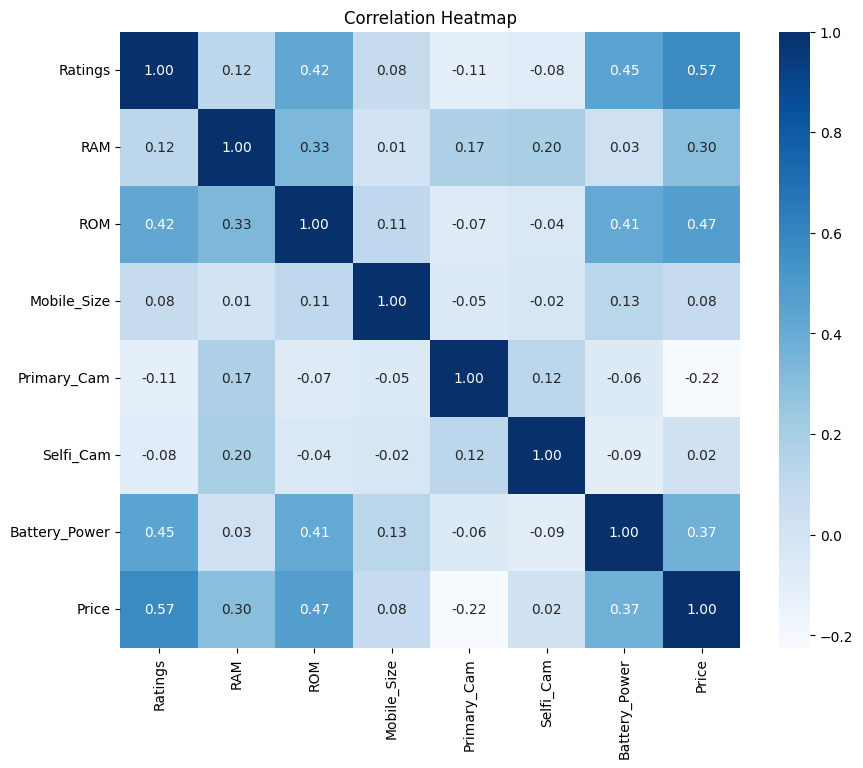

In [ ]:
# Calculate the correlation matrix for the DataFrame to understand the relationships between numerical variables
corr = df.corr()

# Set up the figure for the heatmap with a size of 10x8 inches
plt.figure(figsize=(10, 8))

# Plot the heatmap of the correlation matrix
# annot=True adds the correlation coefficients on the heatmap
# cmap='Blues' specifies the color map
# fmt='.2f' formats the annotation to two decimal places
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')

# Add a title to the heatmap
plt.title('Correlation Heatmap')

# Display the heatmap
plt.show()

### Interpretation:

- Which features have the strongest positive correlation with `Price`?
  - The features with the strongest positive correlation with `Price` are `Ratings` (0.57), `ROM` (0.47), and `Battery_Power` (0.37). This suggests that higher ratings, more ROM, and higher battery power tend to be associated with higher prices.

- Is there any feature with a negative correlation with `Price`?
  - Yes, `Primary_Cam` has a negative correlation with `Price` (-0.22). This indicates that, in this dataset, a higher primary camera resolution might be associated with a lower price, which could be due to various factors like older technology being cheaper.

- How strongly are `RAM` and `Price` correlated?
  - `RAM` has a moderate positive correlation with `Price` (0.30), indicating that as RAM increases, the price tends to increase as well, though the relationship is not as strong as with some other features.

- What is the relationship between `Ratings` and `Battery_Power`?
  - `Ratings` and `Battery_Power` have a moderate positive correlation (0.45), suggesting that phones with higher battery power tend to receive better ratings.

- Are there any features that have little to no correlation with `Price`?

  - `Selfi_Cam` (0.02) and `Mobile_Size` (0.08) show very little correlation with `Price`, indicating that these features might not be significant factors in determining the price of a mobile phone in this dataset.

- Is there any strong correlation between the features?

  - Yes, `ROM` and `Battery_Power` have a moderate positive correlation (0.41), indicating that devices with more ROM also tend to have higher battery power. Similarly, `Ratings` and `ROM` have a correlation of 0.42, suggesting that better-rated phones also tend to have more ROM.

## 1.5 Model Building

### 1.5.1 Linear Regression

- `df.column` lists down the names of all the columns of the dataframe `df`.
- `train_test_split()` helps to split the data into training and test datsets.
- `StandardScaler` from `sklearn.preprocessing` helps to scale the data before modelling.
- `OLS()` from `sm` (`statsmodels` library) helps to fit a linear regression model on the data. This is done as `model = sm.OLS(y_train, X_train).fit()`.
- `model.summary()` provides a detailed summary with all the metrics of the fitted linear regression model.

In [ ]:
# Check the columns of the data to identify the features
df.columns

Index(['Ratings', 'RAM', 'ROM', 'Mobile_Size', 'Primary_Cam', 'Selfi_Cam',
       'Battery_Power', 'Price'],
      dtype='object')

In [ ]:
# Select features and target variable for regression
features = ['Ratings', 'RAM', 'ROM', 'Mobile_Size', 'Primary_Cam', 'Selfi_Cam',
       'Battery_Power']
# Split the data into features (X) and target (y)
X = df[features]
y = df['Price']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check the data
X_train[:5]

,Ratings,RAM,ROM,Mobile_Size,Primary_Cam,Selfi_Cam,Battery_Power
788,4.5,6.0,128.0,6.39,48,13.0,3800
637,4.0,6.0,32.0,4.50,48,8.0,3000
444,3.9,6.0,32.0,4.50,48,11.0,3000
332,4.3,3.0,32.0,6.22,38,8.0,4030
291,3.8,6.0,32.0,4.54,25,8.0,3000


In [ ]:
# Standardize the features
# Import the library
from sklearn.preprocessing import StandardScaler

# Initialize a scaler
scaler = StandardScaler()

# Scale the train and test data
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Check the data
X_train[:5]

array([[ 1.05672500e+00,  1.50829992e-03,  1.17842235e+00,
         2.07926298e-01,  1.41105799e-02,  9.23705036e-01,
         5.72882573e-01],
       [-3.03729343e-01,  1.50829992e-03, -6.04108782e-01,
        -2.83960196e-01,  1.41105799e-02, -1.84947268e-01,
        -2.83292851e-01],
       [-5.75820212e-01,  1.50829992e-03, -6.04108782e-01,
        -2.83960196e-01,  1.41105799e-02,  4.80244115e-01,
        -2.83292851e-01],
       [ 5.12543265e-01, -1.45777187e+00, -6.04108782e-01,
         1.63682539e-01, -8.69513114e-01, -1.84947268e-01,
         8.19033007e-01],
       [-8.47911081e-01,  1.50829992e-03, -6.04108782e-01,
        -2.73549900e-01, -2.01822392e+00, -1.84947268e-01,
        -2.83292851e-01]])

In [ ]:
# Model Building using statsmodels library
# Import the modules
from statsmodels.formula.api import ols
import statsmodels.api as sm

# Add the intercept term
X = sm.add_constant(X)

# Splitting the data in 70:30 ratio of train to test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30 , random_state = 1)


# Create the model
model1 = sm.OLS(y_train, X_train).fit()

# Get the model summary
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     67.33
Date:                Fri, 13 Sep 2024   Prob (F-statistic):           4.27e-70
Time:                        19:37:46   Log-Likelihood:                -6330.0
No. Observations:                 564   AIC:                         1.268e+04
Df Residuals:                     556   BIC:                         1.271e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -1.044e+05   1.06e+04     -9.877      0.000   -1.25e+05   -8.36e+04
Ratings        2.595e+04   2477.259     10.476      0.000    2.11e+04    3.08e+04
RAM            2652.9417    427.778      6.202      0.000    1812.682    3493.201
ROM              75.0025     17.812      4.211      0.000      40.016     109.989
Mobile_Size      -6.7907    165.372     -0.041      0.967    -331.621     318.040
Primary_Cam    -445.4488     71.872     -6.198      0.000    -586.623    -304.275
Selfi_Cam       371.3071    179.719      2.066      0.039      18.297     724.318
Battery_Power     3.0023      0.934      3.215      0.001       1.168       4.836
==============================================================================
Omnibus:                      383.490   Durbin-Watson:                   1.982
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4736.840
Skew:                           2.891   Prob(JB):                         0.00
Kurtosis:                      15.967   Cond. No.                     4.78e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.78e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Interpretation:
- What do you think about the metrics?
  - The model has poor metrics.
- Does the data suffers from multicollinearity?
  - The summary indicates that the data suffers from multicollinearity.

### 1.5.2 Multicollinearity Analysis
Checking for multicollinearity involves assessing the degree to which independent variables in a regression model are highly correlated with each other.

- **Variance Inflation Factor:**

  - VIF, or Variance Inflation Factor, is a measure used to detect the presence of multicollinearity in a regression model.

  - High VIF values indicate that a predictor variable is highly correlated with other predictors, which can make the coefficient estimates unstable and difficult to interpret.
  - Low VIF values suggest little to no multicollinearity.

- **Interpreting VIF values:**
  - **VIF = 1:** No multicollinearity; the predictor is not correlated with other variables.
  - **1 < VIF ≤ 5:** Low to moderate multicollinearity; generally acceptable but worth monitoring.
  - **VIF > 5:** Indicates moderate multicollinearity; may start affecting the reliability of the model's coefficients.
  - **VIF > 10:** High multicollinearity; problematic and often signals that the variable should be removed or combined with others.

In [ ]:
# Import the required modules
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Assuming df is your DataFrame and it is already loaded
# Remove non-numeric columns if any
df_numeric = df.select_dtypes(include=[float, int])

# Define a function to calculate VIF for each feature
def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) for i in range(len(df.columns))]
    return vif_data

# Calculate VIF for the dataset
vif_df = calculate_vif(df_numeric)

# Display the VIF values
print(vif_df)

         Feature        VIF
0        Ratings  41.563787
1            RAM  11.955536
2            ROM   3.684761
3    Mobile_Size   3.067169
4    Primary_Cam  21.168871
5      Selfi_Cam   5.024410
6  Battery_Power  18.591624
7          Price   2.157319


### Interpretation:

- Which features exhibit high multicollinearity?

  - The features `Ratings` (VIF = 41.56), `Primary_Cam` (VIF = 21.17), `Battery_Power` (VIF = 18.59), and `RAM` (VIF = 11.96) exhibit high multicollinearity. These VIF values are significantly higher than 5, indicating that these features are highly correlated with other features in the dataset.


- What action should be considered for features with high VIF values?

  - For features with high VIF values, such as `Ratings`, `Primary_Cam`,`Battery_Power`, and `RAM`, you should consider removing or combining them or use advanced models like random forest.



### 1.5.3 Random Forest Regressor

The Random Forest Regressor is an advanced machine learning algorithm that combines multiple classifiers(decision trees) to improve predictive accuracy and control overfitting.  The final prediction is obtained by averaging the predictions from all the individual classifiers. This approach reduces the variance of the model and is particularly effective in handling large datasets and capturing complex relationships between variables. Random Forest Regressors are also robust to multicollinearity and can provide insights into feature importance.

*Note: You will learn about decision trees and random forest working in the later sessions through this course.*

- `RandomForestRegressor` from `sklearn.ensemble` leps to fit a random forest regressor.

In [ ]:
# Import the module
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
rf_regressor.fit(X_train, y_train)

# Predict on the test data
y_pred = rf_regressor.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print the evaluation metrics
print("Linear Regression Model Evaluation:")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R2): {r2}")

Linear Regression Model Evaluation:
Mean Absolute Error (MAE): 2185.0677263544635
Mean Squared Error (MSE): 30606292.826624144
R-squared (R2): 0.9144602045037756


### Interpretation:
- Does the model perform well?
  - The model performs well as it is robust to multicollinearity and also good in capturing complex relationships.



### 1.5.4 Visualizing the result

- `sns.scatterplot()` helps to plot the true values vs predicted values.
- `plot()` helps to draw the diagonal line showing the fitted regression line.

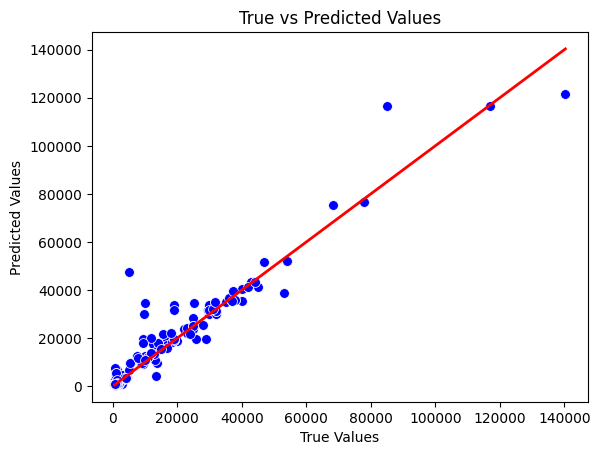

In [ ]:
# Create a scatter plot of true values (y_test) vs. predicted values (y_pred)
sns.scatterplot(x=y_test, y=y_pred, color='blue', s=50)

# Add a diagonal line (red) that represents the ideal scenario where predicted values match the true values
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', lw=2)  # Diagonal line

# Label the x-axis as 'True Values'
plt.xlabel('True Values')

# Label the y-axis as 'Predicted Values'
plt.ylabel('Predicted Values')

# Set the title of the plot to 'True vs Predicted Values'
plt.title('True vs Predicted Values')

# Display the plot
plt.show()

### Interpretation:
- What does the plot indicate about the model predictions?
  - The scatter plot shows that the model's predictions generally align well with the true values, especially for lower values. However, there are some deviations, particularly for higher values.
<hr> <hr>

#2. Classification Models


## 2.1 Dataset Description

Bob has started his own mobile company. He wants to give tough fight to big companies like Apple,Samsung etc.

He does not know how to estimate price of mobiles his company creates. In this competitive mobile phone market you cannot simply assume things. To solve this problem he collects sales data of mobile phones of various companies.

Bob wants to find out some relation between features of a mobile phone(eg:- RAM,Internal Memory etc) and its selling price. But he is not so good at Machine Learning. So he needs your help to solve this problem.

In this problem you do not have to predict actual price but a price range indicating how high the price is.

<center><img src="https://miro.medium.com/v2/resize:fit:1400/1*D7TDOkHIH8hmbYQtCZ856A.jpeg" width=500/></center>

Dataset as 21 features and 2000 entries. The meanings of the features are given below.

- `battery_power`: Total energy a battery can store in one time measured in mAh
- `blue`: Has bluetooth or not
- `clock_speed`: speed at which microprocessor executes instructions
- `dual_sim`: Has dual sim support or not
- `fc`: Front Camera mega pixels
- `four_g`: Has 4G or not
- `int_memory`: Internal Memory in Gigabytes
- `m_dep`: Mobile Depth in cm
- `mobile_wt`: Weight of mobile phone
- `n_cores`: Number of cores of processor
- `pc`: Primary Camera mega pixels
- `px_height`: Pixel Resolution Height
- `px_width`: Pixel Resolution Width
- `ram`: Random Access Memory in Mega Byte
- `sc_h`: Screen Height of mobile in cm
- `sc_w`: Screen Width of mobile in cm
- `talk_time`: longest time that a single battery charge will last when you are
- `three_g`: Has 3G or not
- `touch_screen`: Has touch screen or not
- `wifi`: Has wifi or not
-`price_range`: This is the target variable with value of 0(low cost), 1(medium cost), 2(high cost) and 3(very high cost)


## 2.2 Importing the required libraries & modules

In [ ]:
# Import the warnings module, which allows control over warning messages
import warnings

# Suppress all warnings in the script
warnings.filterwarnings("ignore")

In [ ]:
# Importing libraries for numerical operations and data manipulation
import numpy as np     # For numerical computations and array manipulations
import pandas as pd    # For handling DataFrames, and data loading, cleaning, and manipulation

# Importing libraries for data visualization
import matplotlib.pyplot as plt  # For creating basic plots (histograms, scatter plots, etc.)
import seaborn as sns            # For enhanced and more aesthetically pleasing visualizations

# Importing machine learning models and evaluation metrics
from sklearn.naive_bayes import GaussianNB                      # Gaussian Naive Bayes classifier
from sklearn.neighbors import KNeighborsClassifier              # K-Nearest Neighbors (KNN) classifier
from sklearn.linear_model import LogisticRegression             # Logistic Regression classifier

# Importing utilities for model evaluation and hyperparameter tuning
from sklearn.model_selection import train_test_split, GridSearchCV  # For splitting the dataset into training and test sets, and grid search for hyperparameter tuning

# Importing evaluation metrics for classification tasks
from sklearn.metrics import (accuracy_score, classification_report,  # Metrics to evaluate model performance
                             precision_score, recall_score,
                             f1_score, confusion_matrix)


## 2.3 Loading & Viewing the data

- `read_csv()` helps to load a csv file.
- `head()` helps to view the initial few rows of the dataset.
- `df.shape` gives the shape (rows by columns) of the dataset `df`.

In [ ]:
# Load the dataset
df = pd.read_csv('mobile_data_new.csv')

# View the data
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [ ]:
# Get the shape of the DataFrame
df.shape

(2000, 21)

## 2.4 Exploratory Data Analysis (EDA)


### 2.4.1 Basic Information

- `info()` helps to get the basic information about the dataset.
- `value_counts()` count the number of occurrences of each unique value in a DataFrame column.


In [ ]:
# Get the basic info of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

### Interpretation:
- Are there any null values in the dataset?
  - The dataset is clean and has no null values


### 2.4.2 Examine the Target Variable


In [ ]:
# Check the target variable distribution
df['price_range'].value_counts(normalize=True)


,proportion
price_range,
1,0.25
2,0.25
3,0.25
0,0.25


### Interpretation:

- Does the dataset have class imbalance?
  - There is no class imbalance.

### 2.4.3 Correlation Analysis

*Hint: Use heatmap*
- `corr()` calculates the correlation between columns in a DataFrame.
- `sns.heatmap()` helps to visualize the correlation values as a color coded matrix.

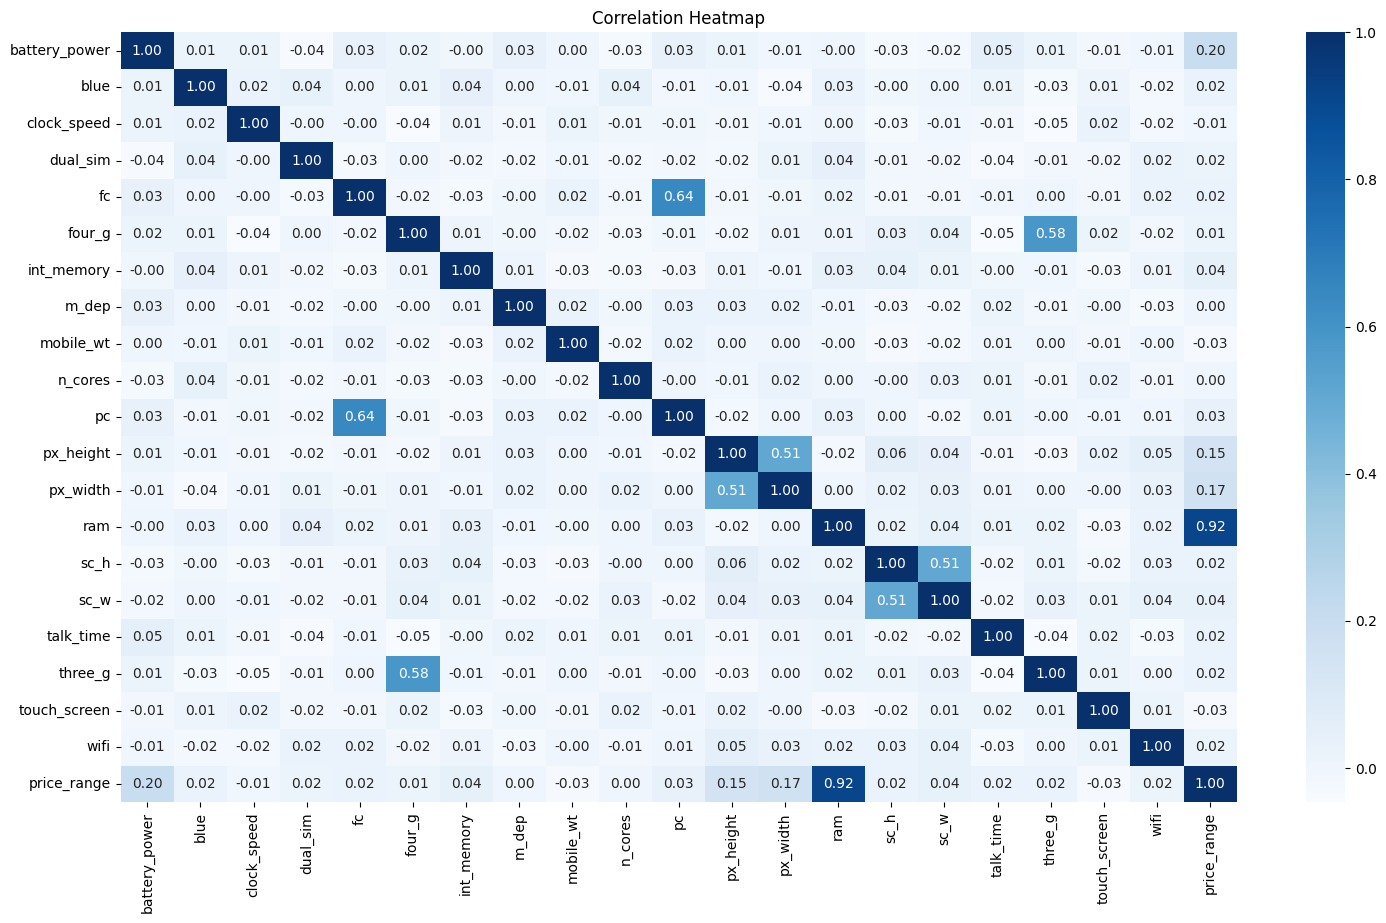

In [ ]:
# Calculate the correlation matrix for the DataFrame to understand the relationships between numerical variables
corr = df.corr()

# Set up the figure for the heatmap with a size of 10x8 inches
plt.figure(figsize=(18, 10))

# Plot the heatmap of the correlation matrix
# annot=True adds the correlation coefficients on the heatmap
# cmap='Blues' specifies the color map
# fmt='.2f' formats the annotation to two decimal places
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')

# Add a title to the heatmap
plt.title('Correlation Heatmap')

# Display the heatmap
plt.show()

### Interpretation:

- Which features are most strongly correlated with the target variable `price_range`?
   - The feature `ram` shows the strongest positive correlation with `price_range` at 0.92. This suggests that as the amount of `ram` increases, the `price_range` also tends to increase significantly.

- Are there any features that have a notable correlation with each other?
  - Yes, the following pairs of features show notable correlations:

    - `px_width` and `px_height` have a strong positive correlation of 0.51, indicating that the width and height of pixels tend to increase together.
    - `pc` and `fc` (primary camera and front camera megapixels) have a moderate positive correlation of 0.64, suggesting that phones with better primary cameras also tend to have better front cameras.
    - `three_g` and `four_g` have a moderate positive correlation of 0.58, which implies that phones supporting 4G also likely support 3G.





## 2.5 Feature Engineering

### 2.5.1 Create new features based on highly correlated ones to avoid multicollinearity


In [ ]:
# 1. Total Pixel Resolution (`px_total`)
df['px_total'] = df['px_height'] * df['px_width']

# 2. Camera Quality Score (`cam_quality`)
df['cam_quality'] = df['pc'] + df['fc']

# 3. Mobile Volume (`mobile_volume`)
df['mobile_volume'] = df['sc_h'] * df['sc_w'] * df['m_dep']

# 7. Screen Aspect Ratio (`screen_aspect_ratio`)
df['screen_area'] = df['sc_h'] * df['sc_w']

# Dropping the original features
df = df.drop(columns=['px_height', 'px_width', 'pc', 'fc', 'sc_h', 'sc_w', 'm_dep'])

# Display the first few rows to check the new features
df.head()


,battery_power,blue,clock_speed,dual_sim,four_g,int_memory,mobile_wt,n_cores,ram,talk_time,three_g,touch_screen,wifi,price_range,px_total,cam_quality,mobile_volume,screen_area
0,842,0,2.2,0,0,7,188,2,2549,19,0,0,1,1,15120,3,37.8,63
1,1021,1,0.5,1,1,53,136,3,2631,7,1,1,0,2,1799140,6,35.7,51
2,563,1,0.5,1,1,41,145,5,2603,9,1,1,0,2,2167308,8,19.8,22
3,615,1,2.5,0,0,10,131,6,2769,11,1,0,0,2,2171776,9,102.4,128
4,1821,1,1.2,0,1,44,141,2,1411,15,1,1,0,1,1464096,27,9.6,16


In [ ]:
# Separate the features (X) and the target variable (y) for the  data
X, y = df.drop(['price_range'], axis = 1), df[['price_range']]


## 2.6 Model Building
### 2.6.1 Spliting Train and Test data

- `train_test_split()` helps to split the data into training and test datsets.


In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42)
# Check the data
X_train[:5]

,battery_power,blue,clock_speed,dual_sim,four_g,int_memory,mobile_wt,n_cores,ram,talk_time,three_g,touch_screen,wifi,px_total,cam_quality,mobile_volume,screen_area
968,1923,0,0.5,1,0,46,191,1,1489,3,1,1,1,1349153,17,45.0,90
240,633,1,2.2,0,1,49,139,8,3560,16,1,1,1,533761,1,1.1,11
819,1236,0,0.9,1,1,57,188,1,1406,20,1,0,1,418253,16,16.8,168
692,781,0,1.1,0,0,38,198,5,3508,5,0,0,1,508896,9,41.6,104
420,1456,1,0.5,1,0,7,105,5,1587,20,1,0,1,908592,19,12.0,30


### 2.6.2 Feature Scaling

- `StandardScaler` from `sklearn.preprocessing` helps to scale the data before modelling.


In [ ]:
# Import the library
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler, which will standardize features by removing the mean and scaling to unit variance
scaler = StandardScaler()

# Fit the scaler on the training data and apply the transformation (standardization) to X_train
X_train = scaler.fit_transform(X_train)
# Apply the same transformation to the test data (X_test) using the already fitted scaler
X_test = scaler.transform(X_test)

## 2.7 Model Building

Make sure the following imports are done for model building.
```
from sklearn.naive_bayes import GaussianNB  

from sklearn.neighbors import KNeighborsClassifier  

from sklearn.linear_model import LogisticRegression
```

- `classification_report()` from `sklearn.metrics` helps to view the model metrics.

           


### 2.7.1 KNN Algorithm

In [ ]:
# Initialize the KNN model
model = KNeighborsClassifier()

# Fit the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

# Print classification report
print('Classification Report:')
print(classification_report(y_test, y_pred))

Accuracy: 0.5200
Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.72      0.68       105
           1       0.34      0.37      0.36        91
           2       0.38      0.43      0.40        92
           3       0.78      0.52      0.62       112

    accuracy                           0.52       400
   macro avg       0.53      0.51      0.51       400
weighted avg       0.55      0.52      0.53       400



### Interpretation:
- Which class does the model perform best and worst on?
  - The model performs best on `Class 3` with a precision of 0.78 and an f1-score of 0.62. It performs worst on `Class 1` with a precision of 0.34 and an f1-score of 0.36.

- Do you think the value of `k` has impacted the performance?
  - Yes, the value of `k` (the number of neighbors considered in the KNN algorithm) can significantly impact the performance of the model. Choosing the right k is crucial because it directly influences how well the model generalizes to unseen data.

In [ ]:
# Rebuild the model with 'k' value as 10 and 25

# Initialize the KNN models
model1 = KNeighborsClassifier(n_neighbors=10)
model2 = KNeighborsClassifier(n_neighbors=25)

# Fit the models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

# Make predictions
y_pred1 = model1.predict(X_test)
y_pred2 = model2.predict(X_test)

# Calculate accuracy
accuracy1 = accuracy_score(y_test, y_pred1)
accuracy2 = accuracy_score(y_test, y_pred2)
print(f'Accuracy for model with k=10: {accuracy1:.4f}')
print(f'Accuracy for model with k=25: {accuracy2:.4f}')

# Print classification report
print('Classification Report for model with k=10:')
print(classification_report(y_test, y_pred1))

print('Classification Report for model with k=25:')
print(classification_report(y_test, y_pred2))

Accuracy for model with k=10: 0.5550
Accuracy for model with k=25: 0.6150
Classification Report for model with k=10:
              precision    recall  f1-score   support

           0       0.68      0.78      0.73       105
           1       0.40      0.43      0.41        91
           2       0.38      0.42      0.40        92
           3       0.79      0.55      0.65       112

    accuracy                           0.56       400
   macro avg       0.56      0.55      0.55       400
weighted avg       0.58      0.56      0.56       400

Classification Report for model with k=25:
              precision    recall  f1-score   support

           0       0.70      0.81      0.75       105
           1       0.46      0.51      0.48        91
           2       0.47      0.47      0.47        92
           3       0.83      0.64      0.72       112

    accuracy                           0.61       400
   macro avg       0.61      0.61      0.61       400
weighted avg       0.63  

### Interpretation:
- Which model performed better overall, and what evidence supports this?
  - The model with `k=25` performed better overall compared to the model with `k=10`. This is evident from the higher overall accuracy, which increased from 55.5% with `k=10` to 61.5% with `k=25`. Additionally, the precision, recall, and f1-scores for the model with `k=25` are consistently higher across the board, indicating that this model is more effective at making correct predictions and balancing between false positives and false negatives.

- Should even larger `k` values be considered for further improvement?
  - Given that the model with `k=25` outperformed `k=10`, it might be worth exploring even larger k values to see if performance continues to improve. However, there is often a trade-off: too large a k can lead to underfitting, where the model becomes too generalized. Further experimentation with cross-validation would help in finding the optimal k that maximizes accuracy while maintaining good generalization.

### 2.7.2 Naive Bayes Algorithm

Let's try Gaussian Naive Bayes algorithm.


In [ ]:
# Initialize the Gaussian Naive Bayes model
gnb = GaussianNB()

# Fit the model on the training data
gnb.fit(X_train, y_train)

# Make predictions on the test data
y_pred = gnb.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

# Print classification report
print('Classification Report:')
print(classification_report(y_test, y_pred))

Accuracy: 0.7925
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89       105
           1       0.77      0.67      0.72        91
           2       0.65      0.77      0.70        92
           3       0.87      0.80      0.84       112

    accuracy                           0.79       400
   macro avg       0.79      0.79      0.79       400
weighted avg       0.80      0.79      0.79       400



### Interpretation:
- Does the Gaussian Naive Bayes model performing better compared to the KNN models? Why?
  - The Gaussian Naive Bayes model is likely performing better because it assumes that the features follow a normal distribution, which might closely match the underlying distribution of the data in this case.
  - Unlike KNN, which relies heavily on the concept of proximity in the feature space, Naive Bayes focuses on the probabilistic relationships between the features and the target variable. This allows it to generalize better, especially in situations where the feature space is complex or where classes are not easily separable by distance alone.
  - Naive Bayes also tends to be more robust in cases where the data might be noisy or where some features are more informative than others.

- Does this model generalize well for all the classes?
  - The model generalizes very well for Classes 0 and 3, making it reliable for these classes.
  - However, for Classes 1 and 2, while the performance is still solid, the model shows some limitations, indicating that it might not generalize as well for these classes as it does for others.

### 2.7.3 Logistic Regression

In [ ]:
# Initialize the Logistic Regression model
log_reg = LogisticRegression(random_state=42)

# Train the model using the training data
log_reg.fit(X_train, y_train)

# Predict on the test set
y_pred = log_reg.predict(X_test)


# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

# Print classification report
print('Classification Report:')
print(classification_report(y_test, y_pred))


Accuracy: 0.9275
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       105
           1       0.91      0.92      0.92        91
           2       0.88      0.88      0.88        92
           3       0.94      0.94      0.94       112

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.93       400
weighted avg       0.93      0.93      0.93       400



### Interpretation:
- How well did the Logistic Regression model perform overall?
  - The Logistic Regression model performed exceptionally well, achieving an overall accuracy of 92.75%. This high accuracy indicates that the model is highly effective at correctly classifying instances across the dataset.

- How does the model perform across different classes in terms of precision, recall, and f1-score?

  - `Class 0`: The model shows excellent performance with a precision of 0.97, recall of 0.96, and an f1-score of 0.97. This indicates that the model is nearly perfect in identifying and correctly classifying instances of `Class 0`.
  - `Class 1`: The model also performs very well for `Class 1`, with a precision of 0.91, recall of 0.92, and an f1-score of 0.92. This shows strong and consistent performance for this class.
  - `Class 2`: The model's performance remains strong for `Class 2`, with a precision, recall, and f1-score all at 0.88. While slightly lower than the other classes, these metrics still reflect a high level of accuracy.
  - `Class 3`: Similar to `Class 0`, the model performs exceptionally well for `Class 3`, with precision, recall, and f1-scores all at 0.94. This indicates a high degree of reliability in classifying this class.

- Why might Logistic Regression be performing better than the previous models?
  - Logistic Regression might be performing better because it is well-suited for binary and multiclass classification problems where the relationship between the features and the target variable is linear or nearly linear.
  - Unlike KNN, which is distance-based, and Naive Bayes, which assumes feature independence, Logistic Regression directly models the probability of class membership using a logistic function. This allows it to effectively capture the relationships in the data, especially when the data is linearly separable or nearly so.
  

### 2.7.3.1 Finding the top 10 features contributing for the classification

In [ ]:
# Get the coefficients from the model
coefficients = log_reg.coef_[0]  # For binary classification, for multiclass use model.coef_

# Create a DataFrame to associate feature names with their coefficients
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

# Take the absolute value of coefficients to sort by importance
feature_importance['Absolute Coefficient'] = feature_importance['Coefficient'].abs()

# Sort the features by the absolute value of their coefficients
top_features = feature_importance.sort_values(by='Absolute Coefficient', ascending=False)

# Display the top features
print(top_features.head(10))  # Display top 10 features

          Feature  Coefficient  Absolute Coefficient
8             ram   -10.503915             10.503915
0   battery_power    -2.625744              2.625744
13       px_total    -2.516479              2.516479
6       mobile_wt     0.369839              0.369839
14    cam_quality    -0.143826              0.143826
3        dual_sim     0.132239              0.132239
10        three_g    -0.120281              0.120281
2     clock_speed     0.098988              0.098988
5      int_memory    -0.093072              0.093072
4          four_g     0.081853              0.081853


### Interpretation:
- What is the top feature affecting the target variable?
  - `ram`. This is in line with the correlation analysis.
- Does this contain any newly created feature variables?
  - Yes. `px_total`, `cam_quality` are the derived features in the list.

<hr> <hr>